<a href="https://colab.research.google.com/github/ramsingh161/DL_CA2/blob/main/Fashion_Item_Generator(final).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import os

from torch.utils.data import DataLoader

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU. Training all 15 epochs may take considerably longer.")


PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

# Normalize images to [-1, 1], matching the generator's Tanh output
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

dataloader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    drop_last=True
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", len(train_dataset))
print("Batches per epoch:", len(dataloader))
print("Number of classes:", len(class_names))


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.3MB/s]

Training images: 60000
Batches per epoch: 468
Number of classes: 10


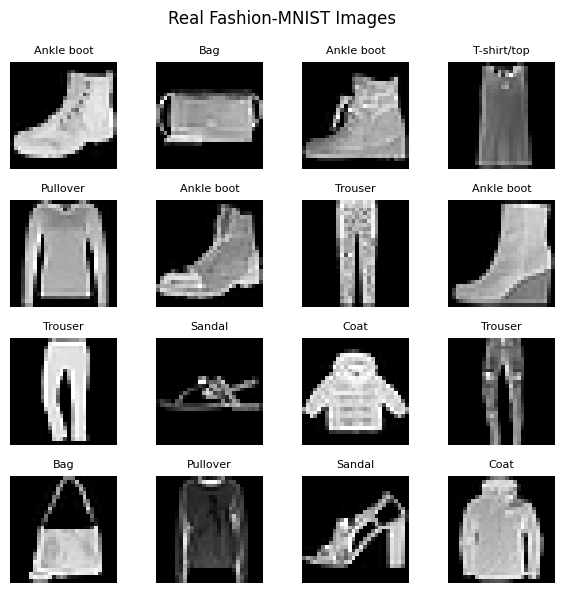

In [ ]:

real_images, labels = next(iter(dataloader))

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    image = real_images[i, 0] * 0.5 + 0.5
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[labels[i].item()], fontsize=8)
    ax.axis("off")

plt.suptitle("Real Fashion-MNIST Images")
plt.tight_layout()
plt.show()


In [ ]:

latent_dim = 100

class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.network = nn.Sequential(
            # 1x1 -> 7x7
            nn.ConvTranspose2d(
                latent_dim, 128, kernel_size=7,
                stride=1, padding=0, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 7x7 -> 14x14
            nn.ConvTranspose2d(
                128, 64, kernel_size=4,
                stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 14x14 -> 28x28
            nn.ConvTranspose2d(
                64, 1, kernel_size=4,
                stride=2, padding=1, bias=False
            ),
            nn.Tanh()
        )

    def forward(self, z):
        return self.network(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            # 28x28 -> 14x14
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # 14x14 -> 7x7
            nn.Conv2d(
                64, 128, kernel_size=4,
                stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, image):
        # Raw logits; sigmoid is handled by BCEWithLogitsLoss
        return self.network(image).view(-1)


G = Generator(latent_dim).to(device)
D = Discriminator().to(device)

print("Generator parameters:",
      sum(p.numel() for p in G.parameters()))

print("Discriminator parameters:",
      sum(p.numel() for p in D.parameters()))


Generator parameters: 759680
Discriminator parameters: 138689


In [ ]:

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers initialized.")


Loss function and optimizers initialized.


In [ ]:

epochs = 15

torch.manual_seed(42)

fixed_noise = torch.randn(
    25, latent_dim, 1, 1, device=device
)

g_losses = []
d_losses = []
sample_images = {}

for epoch in range(epochs):
    G.train()
    D.train()

    total_g = 0.0
    total_d = 0.0

    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, device=device)
        fake_labels = torch.zeros(batch_size, device=device)

        # -------------------------
        # Train the discriminator
        # -------------------------
        optimizer_D.zero_grad(set_to_none=True)

        real_logits = D(real_images)
        loss_real = criterion(real_logits, real_labels)

        noise = torch.randn(
            batch_size, latent_dim, 1, 1, device=device
        )

        fake_images = G(noise)
        fake_logits = D(fake_images.detach())

        loss_fake = criterion(fake_logits, fake_labels)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # -------------------------
        # Train the generator
        # -------------------------
        optimizer_G.zero_grad(set_to_none=True)

        noise = torch.randn(
            batch_size, latent_dim, 1, 1, device=device
        )

        generated_images = G(noise)
        generated_logits = D(generated_images)

        # Generator tries to make fake images appear real
        loss_G = criterion(generated_logits, real_labels)

        loss_G.backward()
        optimizer_G.step()

        total_g += loss_G.item()
        total_d += loss_D.item()

    avg_g = total_g / len(dataloader)
    avg_d = total_d / len(dataloader)

    g_losses.append(avg_g)
    d_losses.append(avg_d)

    # Save generated examples at selected epochs
    G.eval()
    with torch.no_grad():
        generated = G(fixed_noise).cpu()

    if (epoch + 1) in [1, 5, 10, 15]:
        sample_images[epoch + 1] = generated.clone()

    print(
        f"Epoch [{epoch + 1:02d}/{epochs}] "
        f"| Generator Loss: {avg_g:.4f} "
        f"| Discriminator Loss: {avg_d:.4f}"
    )

print("Training complete!")


Epoch [01/15] | Generator Loss: 2.0292 | Discriminator Loss: 0.5838
Epoch [02/15] | Generator Loss: 1.3940 | Discriminator Loss: 0.8207
Epoch [03/15] | Generator Loss: 1.1921 | Discriminator Loss: 0.9771
Epoch [04/15] | Generator Loss: 1.1262 | Discriminator Loss: 1.0403
Epoch [05/15] | Generator Loss: 1.1065 | Discriminator Loss: 1.0591
Epoch [06/15] | Generator Loss: 1.1153 | Discriminator Loss: 1.0561
Epoch [07/15] | Generator Loss: 1.1253 | Discriminator Loss: 1.0523
Epoch [08/15] | Generator Loss: 1.1393 | Discriminator Loss: 1.0521
Epoch [09/15] | Generator Loss: 1.1359 | Discriminator Loss: 1.0420
Epoch [10/15] | Generator Loss: 1.1518 | Discriminator Loss: 1.0447
Epoch [11/15] | Generator Loss: 1.1575 | Discriminator Loss: 1.0382
Epoch [12/15] | Generator Loss: 1.1627 | Discriminator Loss: 1.0349
Epoch [13/15] | Generator Loss: 1.1743 | Discriminator Loss: 1.0311
Epoch [14/15] | Generator Loss: 1.1871 | Discriminator Loss: 1.0231
Epoch [15/15] | Generator Loss: 1.1956 | Discrim

In [ ]:

def show_generated_images(images, title):
    images = images.detach().cpu()

    fig, axes = plt.subplots(5, 5, figsize=(7, 7))

    for i, ax in enumerate(axes.flat):
        image = images[i, 0] * 0.5 + 0.5
        ax.imshow(image.clamp(0, 1), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


for epoch_number in [1, 5, 10, 15]:
    show_generated_images(
        sample_images[epoch_number],
        f"Generated Fashion Images — Epoch {epoch_number}"
    )


NameError: name 'sample_images' is not defined

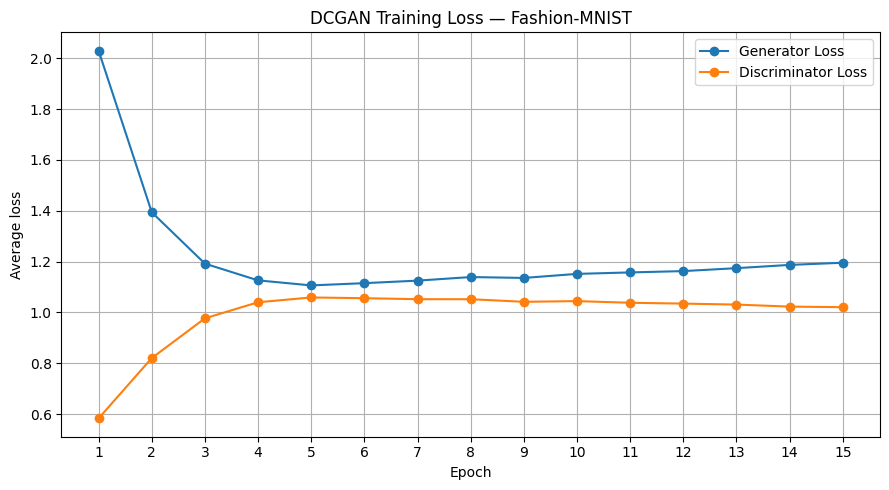

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    g_losses,
    marker="o",
    label="Generator Loss"
)

plt.plot(
    range(1, epochs + 1),
    d_losses,
    marker="o",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("DCGAN Training Loss — Fashion-MNIST")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("training_loss.png", dpi=150)
plt.show()


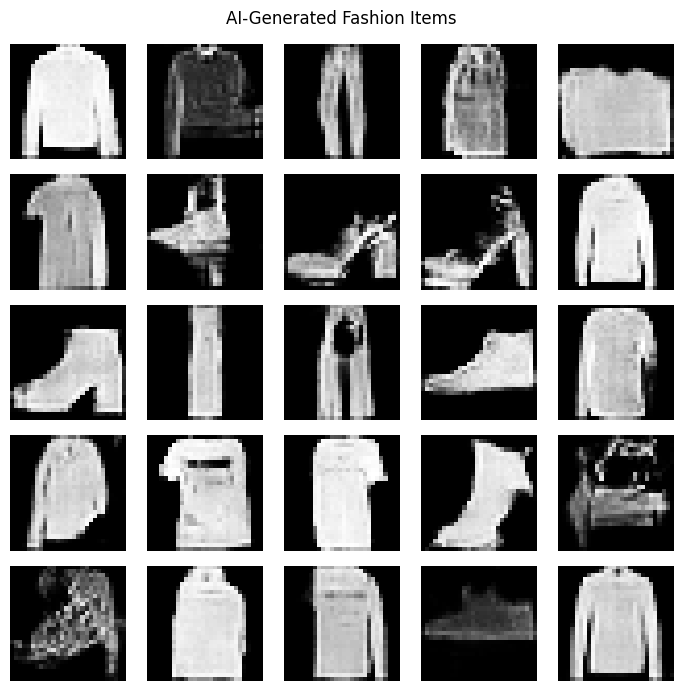

Saved checkpoint, generator weights, and generated images.


In [ ]:

os.makedirs("fashion_gan_results", exist_ok=True)

# Save both models and optimizer states
torch.save({
    "generator": G.state_dict(),
    "discriminator": D.state_dict(),
    "optimizer_G": optimizer_G.state_dict(),
    "optimizer_D": optimizer_D.state_dict(),
    "epochs": epochs,
    "latent_dim": latent_dim
}, "fashion_gan_results/dcgan_checkpoint.pth")

# Save generator separately for future image generation
torch.save(
    G.state_dict(),
    "fashion_gan_results/fashion_generator.pth"
)

# Save final generated image grid
G.eval()

with torch.no_grad():
    final_images = G(fixed_noise).cpu()

fig, axes = plt.subplots(5, 5, figsize=(7, 7))

for i, ax in enumerate(axes.flat):
    image = final_images[i, 0] * 0.5 + 0.5
    ax.imshow(image.clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("AI-Generated Fashion Items")
plt.tight_layout()
plt.savefig(
    "fashion_gan_results/generated_fashion.png",
    dpi=150
)
plt.show()

print("Saved checkpoint, generator weights, and generated images.")


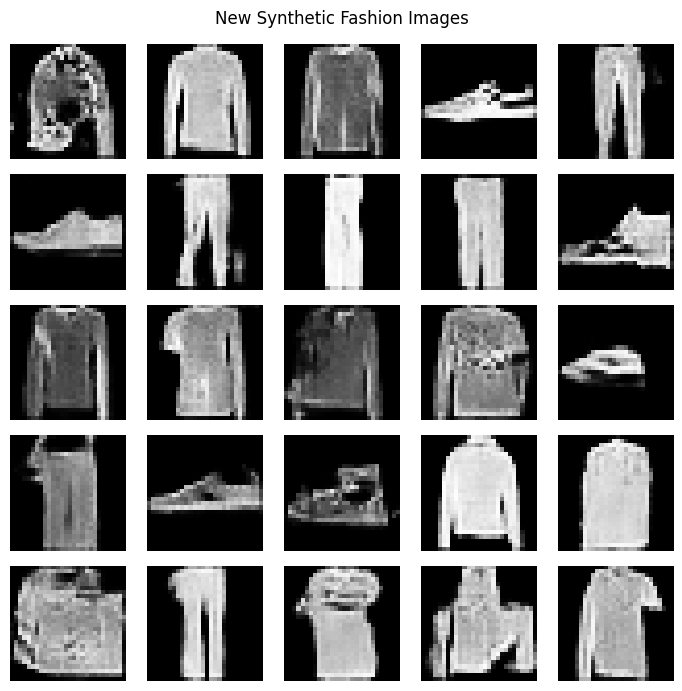

In [ ]:

G.eval()

new_noise = torch.randn(
    25, latent_dim, 1, 1, device=device
)

with torch.no_grad():
    new_images = G(new_noise).cpu()

show_generated_images(
    new_images,
    "New Synthetic Fashion Images"
)
